A cell in your body almost never decides to divide on its own. It waits for permission from outside: a **growth factor** released by a neighbour, a hormone in the blood, contact with the right surface. This chapter follows how such signals cross the membrane and travel to the nucleus, and how the cell powers everything it does by burning sugar. Both topics are central to cancer: the most famous oncogenes (*EGFR*, *KRAS*, *BRAF*, *PIK3CA*) are signalling genes, and cancer cells rewire their metabolism to fuel constant growth.

:::eli5
A cell is like a house with a doorbell. A messenger molecule outside presses the button (a **receptor** on the membrane). Inside, a chain of people pass the message along, each one tapping the next on the shoulder (proteins switching each other on). The last one runs to the control room (the nucleus) and flips switches to turn on the "grow and divide" genes. In cancer, one of the people in the chain is stuck shouting "GROW!" even when nobody rang the bell. Many cancer drugs work by gagging that person.
:::

## Signals and receptors

Most signal molecules (growth factors, many hormones, cytokines) cannot cross the oily membrane, so they bind **receptor** proteins that span it: the outside part grabs the signal and the inside part changes shape and starts the relay. Small fat-soluble hormones (oestrogen, testosterone, cortisol) are the exception: they slip through and bind **nuclear receptors** inside, which act directly as transcription factors.

| Receptor family | How it works | Examples | Drugs |
|---|---|---|---|
| **Receptor tyrosine kinases** (RTKs) | signal brings two receptors together; their kinase domains phosphorylate each other's tyrosines | EGFR, HER2, insulin receptor | erlotinib, osimertinib (EGFR); trastuzumab (HER2) |
| **G-protein-coupled receptors** (GPCRs) | seven membrane helices (chapter P5); activate G proteins and second messengers like cAMP and Ca²⁺ | adrenaline, opioid, histamine receptors | about a third of all approved drugs |
| **Nuclear receptors** | bind hormone inside the cell, then bind DNA | oestrogen receptor, androgen receptor | tamoxifen, enzalutamide |
| **Cytokine receptors** | recruit JAK kinases, which activate STAT transcription factors | interleukin and interferon receptors | ruxolitinib (JAK) |

## Kinase cascades: passing the message

Inside the cell, the commonest way to pass a message is **phosphorylation** (chapter P5): a **kinase** attaches a phosphate group to a target protein, changing its shape and activity, and a **phosphatase** removes it. Humans have about 500 kinases, and many work in chains. The best-known chain, and the most important in cancer, is the **MAPK pathway**:

**growth factor (EGF) → EGFR → RAS → RAF → MEK → ERK → transcription factors (FOS, MYC) → cyclin D → cell division**

- **RAS** is not a kinase but a molecular switch: ON when bound to GTP, OFF after it hydrolyses GTP to GDP. Helper proteins speed up both steps.
- **RAF, MEK and ERK** are kinases, each activating the next.
- A second major branch, **PI3K → AKT → mTOR**, controls cell growth, survival and metabolism.

Cancer mutations hit every level: activating mutations in *EGFR* (lung cancer), *KRAS* (pancreatic, colorectal, lung), *BRAF* (melanoma, with the V600E mutation in about half of cases) and *PIK3CA* (breast); loss of the brake *PTEN*. The commonest *KRAS* mutations (at codon 12) stop RAS from switching off, so the pathway runs without any signal. For 40 years RAS was called "undruggable", until sotorasib (approved 2021) was designed to bind covalently to the cysteine in the KRAS G12C mutant.

Try the playground: switch on the KRAS mutation, then see which inhibitors still work.

::playground animations/signal_lab.html 820

## Why cascades? Amplification and switches

Why use five steps when one would do? One reason is **amplification**: one active receptor activates many RAS molecules, each activates many RAFs, and so on. Another is **ultrasensitivity**: each step responds in a switch-like (sigmoidal) way, and stacking switches makes the overall response even sharper. Let's quantify that with the Hill functions from chapter P6.

:::math
For a response $y = \dfrac{x^n}{K^n + x^n}$, the input needed to go from 10% to 90% of the maximum response rises by a factor $81^{1/n}$. Turning that around, the **effective Hill coefficient** of any sigmoid response is

$$n_\text{eff} = \frac{\log 81}{\log(\text{EC}_{90}/\text{EC}_{10})}.$$

$n_\text{eff} = 1$ is a gentle, hyperbolic response; large $n_\text{eff}$ is a switch.
:::

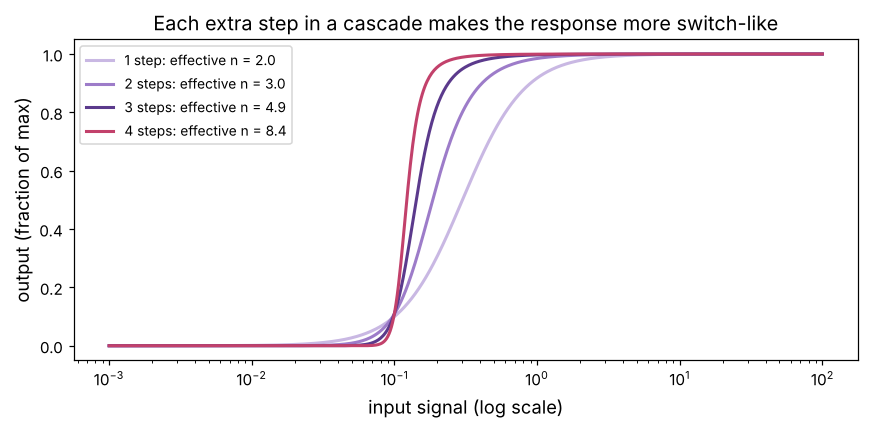

{1: np.float64(2.0), 2: np.float64(3.05), 3: np.float64(4.95), 4: np.float64(8.39)}


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
from scipy.integrate import solve_ivp

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

hill = lambda x, K, n: x ** n / (K ** n + x ** n)
def cascade(x, layers, n=2, K=0.3):
    y = x
    for _ in range(layers):
        y = hill(y, K, n)
    return y / hill(1.0, K, n) if layers else y          # scale so full input gives about full output

def n_eff(xs, ys):
    ys = ys / ys.max()
    ec10, ec90 = np.interp(0.1, ys, xs), np.interp(0.9, ys, xs)
    return np.log(81) / np.log(ec90 / ec10)

xs = np.logspace(-3, 2, 600)
fig, ax = plt.subplots(figsize=(8, 4))
neffs = {}
for layers, c in zip([1, 2, 3, 4], ["#c9b8e3", "#9d7cc9", "#5b3a8c", "#c2416b"]):
    ys = np.array([cascade(x, layers) for x in xs])
    neffs[layers] = n_eff(xs, ys)
    ax.semilogx(xs, ys / ys.max(), color=c, lw=2, label=f"{layers} step{'s' if layers > 1 else ''}: effective n = {neffs[layers]:.1f}")
ax.set_xlabel("input signal (log scale)"); ax.set_ylabel("output (fraction of max)"); ax.legend(fontsize=9)
ax.set_title("Each extra step in a cascade makes the response more switch-like")
save_fig("ultrasensitivity"); plt.show()
R["n1"] = f"{neffs[1]:.1f}"; R["n4"] = f"{neffs[4]:.1f}"
print({k: round(v, 2) for k, v in neffs.items()})

![Figure P9-1. Output of a chain of switch-like steps (each a Hill function with n = 2) against input. More steps make the response steeper: a small change in input flips the output from off to on.](images/ultrasensitivity.png)

One step with $n = 2$ has an effective Hill coefficient of 2.0; four steps reach about 8.4. James Ferrell and colleagues measured exactly this kind of switch in the MAPK cascade of frog eggs in 1996. A switch is what a cell needs for an all-or-nothing decision such as "divide" or "don't".

## Feedback: adaptation and drug resistance

Real pathways are full of **feedback loops**. ERK, for example, phosphorylates and inhibits proteins upstream of RAS, damping its own activation. Negative feedback makes the response **adapt** (peak, then settle lower) and makes the pathway robust: if something halves one step, the feedback partly compensates. That robustness becomes a problem when the "something" is a drug.

Here is a small model of the pathway: receptor R, RAS, RAF, MEK and ERK, each relaxing towards a Hill function of the step above, with ERK inhibiting the activation of RAS.

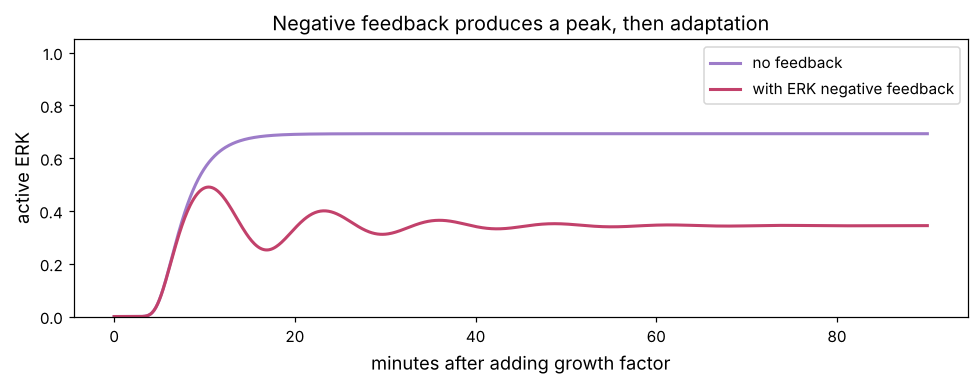

In [2]:
def pathway(t, y, ligand, feedback=True, mek_block=0.0, kras_mut=False):
    Rc, ras, raf, mek, erk = y
    lig = ligand(t)
    fb = 1 / (1 + erk / 0.15) if feedback else 1.0
    ras_drive = 1.0 if kras_mut else Rc * fb
    return [0.3 * (hill(lig, 0.5, 1) - Rc),
            0.5 * (hill(ras_drive, 0.3, 2) - ras),
            0.6 * (hill(ras, 0.3, 2) - raf),
            0.6 * (hill(raf, 0.5, 2) * (1 - mek_block) - mek),
            0.6 * (hill(mek, 0.5, 2) - erk)]

t_eval = np.linspace(0, 90, 900)
step = lambda t: 0.6
fig, ax = plt.subplots(figsize=(9, 3.6))
for fbk, c, lab in [(False, "#9d7cc9", "no feedback"), (True, "#c2416b", "with ERK negative feedback")]:
    sol = solve_ivp(pathway, (0, 90), [0] * 5, t_eval=t_eval, args=(step, fbk), max_step=0.2)
    ax.plot(sol.t, sol.y[4], color=c, lw=2, label=lab)
ax.set_xlabel("minutes after adding growth factor"); ax.set_ylabel("active ERK"); ax.legend(); ax.set_ylim(0, 1.05)
ax.set_title("Negative feedback produces a peak, then adaptation")
save_fig("feedback"); plt.show()

![Figure P9-2. Active ERK after growth factor is added at time 0. Without feedback, ERK rises and stays high; with ERK feedback on RAS activation, it overshoots, rings, and settles at a lower level.](images/feedback.png)

The ringing is a hint of something real: make the feedback stronger or slower and the model oscillates indefinitely (try `(erk / 0.3) ** 4` in place of `erk / 0.15`). Single-cell imaging shows that ERK activity often comes in pulses, and cells appear to read the pulse frequency as part of the message.

Now the consequence for drugs. Block MEK by increasing amounts and compare the steady ERK output with and without the feedback:

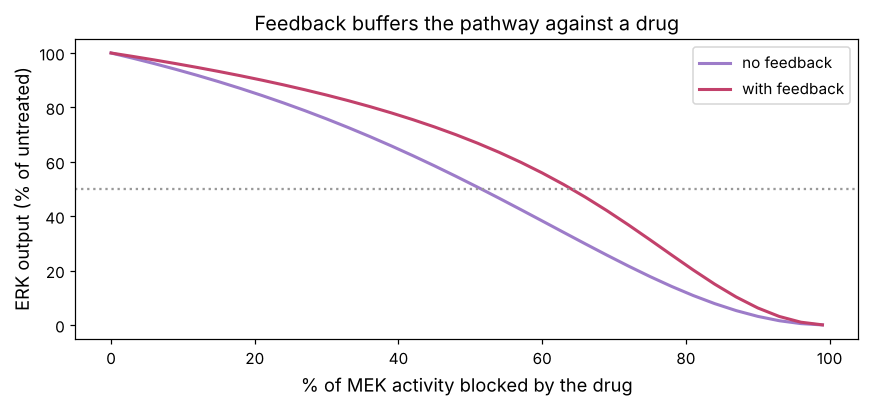

MEK block needed to halve ERK: 52% without feedback, 64% with feedback


In [3]:
def steady_erk(block, feedback, kras_mut=False):
    sol = solve_ivp(pathway, (0, 400), [0] * 5, args=(step, feedback, block, kras_mut), t_eval=np.linspace(300, 400, 101), max_step=0.5)
    return sol.y[4].mean()                               # average over the last 100 minutes

blocks = np.linspace(0, 0.99, 34)
fig, ax = plt.subplots(figsize=(8, 3.8))
res = {}
for fbk, c, lab in [(False, "#9d7cc9", "no feedback"), (True, "#c2416b", "with feedback")]:
    e = np.array([steady_erk(b, fbk) for b in blocks])
    res[fbk] = e / e[0]
    ax.plot(100 * blocks, 100 * e / e[0], color=c, lw=2, label=lab)
ax.axhline(50, color="0.6", ls=":")
ax.set_xlabel("% of MEK activity blocked by the drug"); ax.set_ylabel("ERK output (% of untreated)"); ax.legend()
ax.set_title("Feedback buffers the pathway against a drug")
save_fig("feedback_drug"); plt.show()
half = {k: 100 * np.interp(0.5, v[::-1], blocks[::-1]) for k, v in res.items()}
R["half_nofb"] = f"{half[False]:.0f}"; R["half_fb"] = f"{half[True]:.0f}"
print(f"MEK block needed to halve ERK: {half[False]:.0f}% without feedback, {half[True]:.0f}% with feedback")

![Figure P9-3. Steady ERK activity as a MEK inhibitor blocks more and more MEK. With negative feedback, blocking MEK lowers ERK, which relieves the feedback and pushes more signal into the top of the pathway, so the drug has to work harder.](images/feedback_drug.png)

Without feedback, blocking 52% of MEK halves ERK output. With feedback, it takes 64%. As the drug lowers ERK, the brake on RAS is released and more signal flows in from the top. This **feedback reactivation** is a real reason kinase inhibitors work less well than expected, and why combinations (for example BRAF plus MEK inhibitors in melanoma, or adding an EGFR antibody to a BRAF inhibitor in colorectal cancer) often beat single drugs. Chapter 17 builds larger network models of this kind.

## Metabolism: where the energy comes from

Every process in this course so far (copying DNA, making proteins, pumping ions, moving chromosomes) is paid for in **ATP**, the cell's energy currency (chapter P2). Cells make ATP mainly by breaking down glucose, in three stages:

| Stage | Where | Needs oxygen? | ATP per glucose |
|---|---|---|---|
| **Glycolysis**: glucose (6 carbons) → 2 pyruvate (3 carbons) | cytosol | no | 2 |
| **Citric acid (TCA, Krebs) cycle**: pyruvate → CO₂, loading electron carriers (NADH, FADH₂) | mitochondria | indirectly | 2 |
| **Oxidative phosphorylation**: electrons flow to O₂ through the electron transport chain; the energy pumps protons; ATP synthase uses the proton flow | inner mitochondrial membrane | yes | about 26 |

So complete burning yields about **30 ATP per glucose**, while glycolysis alone gives only 2. Without oxygen (in hard-working muscle, or deep in a tumour, chapter P1), cells convert pyruvate to **lactate** to keep glycolysis running.

How much ATP do you go through?

In [4]:
kcal_per_day = 2000
kj = kcal_per_day * 4.184
efficiency = 0.4                  # fraction of food energy captured as ATP
dG_atp = 50                       # kJ released per mole of ATP hydrolysed in cells
mol_atp = kj * efficiency / dG_atp
mass_kg = mol_atp * 507 / 1000    # ATP molar mass 507 g/mol
body_atp_g = 50                   # roughly how much ATP the body holds at any moment
print(f"ATP turned over per day: {mol_atp:.0f} mol = {mass_kg:.0f} kg")
print(f"each ATP molecule is recycled about {mass_kg * 1000 / body_atp_g:.0f} times a day")
R["atp_kg"] = f"{mass_kg:.0f}"; R["recycle"] = f"{mass_kg * 1000 / body_atp_g:,.0f}"

ATP turned over per day: 67 mol = 34 kg
each ATP molecule is recycled about 679 times a day


You turn over roughly 34 kg of ATP a day, about half your body weight, yet you hold only about 50 g at any moment. Each ATP is recycled about 679 times a day.

### The Warburg effect

In the 1920s Otto Warburg noticed that tumours consume glucose voraciously and turn much of it into lactate *even when oxygen is available*, a seemingly wasteful choice (2 ATP instead of 30). One modern explanation: dividing cells need building materials as much as energy, and glycolysis intermediates feed the synthesis of nucleotides, amino acids and lipids. Another is that glycolysis makes ATP faster per unit of enzyme than mitochondria, so when the cell's protein budget is the limit, a fast but wasteful route wins (as in yeast fermenting sugar into alcohol).

**Flux balance analysis** (FBA) is a standard computational method for metabolism: write down each reaction's stoichiometry, demand that every internal metabolite is produced as fast as it is used (steady state), add limits on uptake and capacity, and find the flows (**fluxes**) that maximise an objective, such as ATP production, with linear programming. A three-reaction toy version already shows the Warburg switch:

:::math
Unknown fluxes: $v_1$ glycolysis (glucose → 2 pyruvate + 2 ATP), $v_2$ respiration (pyruvate + 3 O₂ → 14 ATP, so 28 per glucose), $v_3$ lactate export (pyruvate → lactate).

Steady state for pyruvate: $2v_1 - v_2 - v_3 = 0$. Limits: $v_1 \le$ glucose uptake, $3v_2 \le$ oxygen supply, $v_2 \le$ mitochondrial capacity, all fluxes $\ge 0$.

Maximise ATP $= 2v_1 + 14v_2$.
:::

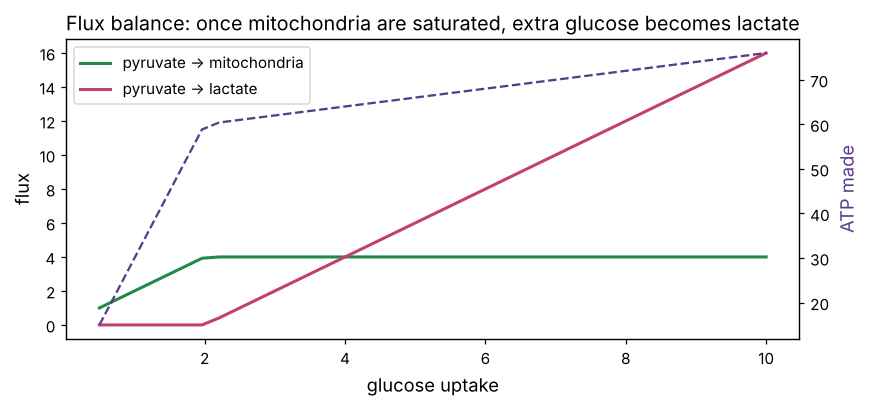

lactate appears once glucose uptake exceeds about 2.2 (= mitochondrial capacity / 2)


In [5]:
from scipy.optimize import linprog
def fba(glucose_max, o2_max, mito_cap):
    c = -np.array([2, 14, 0.0])                         # linprog minimises, so negate the ATP objective
    A_eq, b_eq = [[2, -1, -1]], [0]                       # pyruvate balance
    A_ub = [[1, 0, 0], [0, 3, 0], [0, 1, 0]]
    b_ub = [glucose_max, o2_max, mito_cap]
    r = linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds=[(0, None)] * 3)
    return r.x, -r.fun

uptakes = np.linspace(0.5, 10, 40)
lact, resp, atp = [], [], []
for g in uptakes:
    v, a = fba(g, o2_max=30, mito_cap=4)
    resp.append(v[1]); lact.append(v[2]); atp.append(a)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(uptakes, resp, color="#1f8a4c", lw=2, label="pyruvate → mitochondria")
ax.plot(uptakes, lact, color="#c2416b", lw=2, label="pyruvate → lactate")
ax.set_xlabel("glucose uptake"); ax.set_ylabel("flux"); ax.legend(loc="upper left")
ax2 = ax.twinx(); ax2.plot(uptakes, atp, color="#5b3a8c", ls="--", label="ATP"); ax2.set_ylabel("ATP made", color="#5b3a8c")
ax.set_title("Flux balance: once mitochondria are saturated, extra glucose becomes lactate")
save_fig("fba"); plt.show()
g_switch = uptakes[np.argmax(np.array(lact) > 1e-6)]
R["switch"] = f"{g_switch:.1f}"
print(f"lactate appears once glucose uptake exceeds about {g_switch:.1f} (= mitochondrial capacity / 2)")

![Figure P9-4. A toy flux balance model with plentiful oxygen but limited mitochondrial capacity. At low glucose uptake, all pyruvate is burned. Once the mitochondria are full, extra glucose still yields 2 ATP each through glycolysis, and the surplus pyruvate leaves as lactate: aerobic glycolysis.](images/fba.png)

Even with plenty of oxygen, once glucose uptake passes about 2.2 the optimum is to keep the mitochondria full and push the excess through glycolysis to lactate, because each extra glucose still adds 2 ATP. Real genome-scale FBA models have thousands of reactions (the human model Recon3D has more than 13,000) and are used to predict essential genes and drug targets in cancer cells.

:::bio
Tumour metabolism is visible in the clinic. **FDG-PET** scans inject a radioactive glucose analogue, fluorodeoxyglucose, which cells take up and trap but cannot break down. Tumours, with their high glucose uptake, light up. Some cancers carry mutations in metabolic enzymes themselves: *IDH1* and *IDH2* mutations (in gliomas and leukaemia) make an abnormal metabolite, 2-hydroxyglutarate, that blocks DNA demethylation enzymes and so changes gene regulation (chapter P6). Ivosidenib and enasidenib inhibit the mutant enzymes.
:::

## Signalling meets metabolism: mTOR

The two halves of this chapter meet at **mTOR**, a kinase that integrates growth-factor signals (through PI3K–AKT) with nutrient and energy status (amino acids; the energy sensor AMPK, which reads the ratio of AMP to ATP). When everything is favourable, mTOR switches on protein and lipid synthesis and cell growth; when energy or nutrients are short, it shuts them down and turns on **autophagy** (the cell digesting its own parts for fuel). The PI3K–AKT–mTOR pathway is one of the most frequently activated pathways in cancer, and mTOR inhibitors (everolimus) treat kidney cancer and some breast cancers.

## Summary

| Idea | One line |
|---|---|
| Receptors | RTKs, GPCRs, nuclear receptors, cytokine receptors: the cell's sensors |
| Kinase cascade | EGFR → RAS → RAF → MEK → ERK; amplifies and sharpens signals |
| Oncogenic signalling | mutant KRAS/BRAF/EGFR switch the pathway on without a signal |
| Feedback | negative feedback gives adaptation and robustness, and blunts drugs |
| Energy | glycolysis 2 ATP, full respiration about 30 ATP per glucose |
| Warburg effect | cancers favour glycolysis to lactate even with oxygen; seen by FDG-PET |
| FBA | steady-state flux model solved by linear programming |

:::check
1. Why can a drug that blocks EGFR fail in a tumour with a *KRAS* mutation? *(KRAS is downstream of EGFR and is stuck on, so blocking the receptor doesn't stop the signal.)*
2. What does ultrasensitivity mean, and how do cascades produce it? *(A switch-like response; stacking several sigmoid steps sharpens the overall response.)*
3. How many ATP does a cell get from one glucose with and without oxygen? *(About 30 with full respiration; 2 from glycolysis alone.)*
4. Why does negative feedback make a kinase inhibitor less effective? *(Lowering downstream activity relieves the feedback, increasing upstream input, which partly restores the output.)*
5. What does an FDG-PET scan detect? *(High glucose uptake, typical of many tumours.)*
:::

:::exercise
In the pathway model, a tumour carries a *KRAS* mutation (set `kras_mut=True`). (a) Show that the growth factor no longer matters by comparing steady ERK with ligand 0 and 0.6. (b) Compare how much MEK must be blocked to halve ERK in the mutant. Is the feedback still buffering the drug? Explain why.
:::

<details><summary>Solution</summary>

In [6]:
for lig in [0.0, 0.6]:
    sol = solve_ivp(pathway, (0, 400), [0] * 5, args=(lambda t, L=lig: L, True, 0.0, True), max_step=0.5)
    print(f"KRAS mutant, ligand {lig}: steady ERK = {sol.y[4, -1]:.2f}")
e_mut = np.array([steady_erk(b, True, kras_mut=True) for b in blocks])
print(f"MEK block needed to halve ERK in the KRAS mutant: {100 * np.interp(0.5, (e_mut / e_mut[0])[::-1], blocks[::-1]):.0f}%")

KRAS mutant, ligand 0.0: steady ERK = 0.70
KRAS mutant, ligand 0.6: steady ERK = 0.70


MEK block needed to halve ERK in the KRAS mutant: 52%


With mutant KRAS the pathway is fully on with or without growth factor. In this model the mutant ignores the feedback (the feedback acts on RAS *activation*, and mutant RAS is already locked on), so the drug only has to fight the cascade downstream, and the amount of MEK block needed to halve ERK is set by the shape of the MEK → ERK step alone. In real tumours the picture is more complicated: other feedbacks act on RAF and on receptors that feed wild-type RAS, which is why combinations are still often needed.

</details>